# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Faiz Farrosian Karim | 5054251027 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

try:
    from kneed import KneeLocator
    ada_kneed = True
except ImportError:
    ada_kneed = False

sns.set_style("whitegrid")
RANDOM_STATE = 42


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.

df = pd.read_csv("Live.csv")

print("Jumlah baris dan kolom:", df.shape)
print()
df.info()
print()
display(df.head())
display(df.describe().T)

print("Missing value per kolom:")
print(df.isnull().sum())
print()
print("Jumlah baris duplikat (semua kolom):", df.duplicated().sum())
print("Jumlah baris duplikat (tanpa status_id):", df.drop(columns="status_id").duplicated().sum())
print()
kolom_kosong = [c for c in df.columns if df[c].isnull().all()]
print("Kolom yang seluruhnya kosong:", kolom_kosong)


Jumlah baris dan kolom: (7050, 16)

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), in

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


Missing value per kolom:
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

Jumlah baris duplikat (semua kolom): 0
Jumlah baris duplikat (tanpa status_id): 54

Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


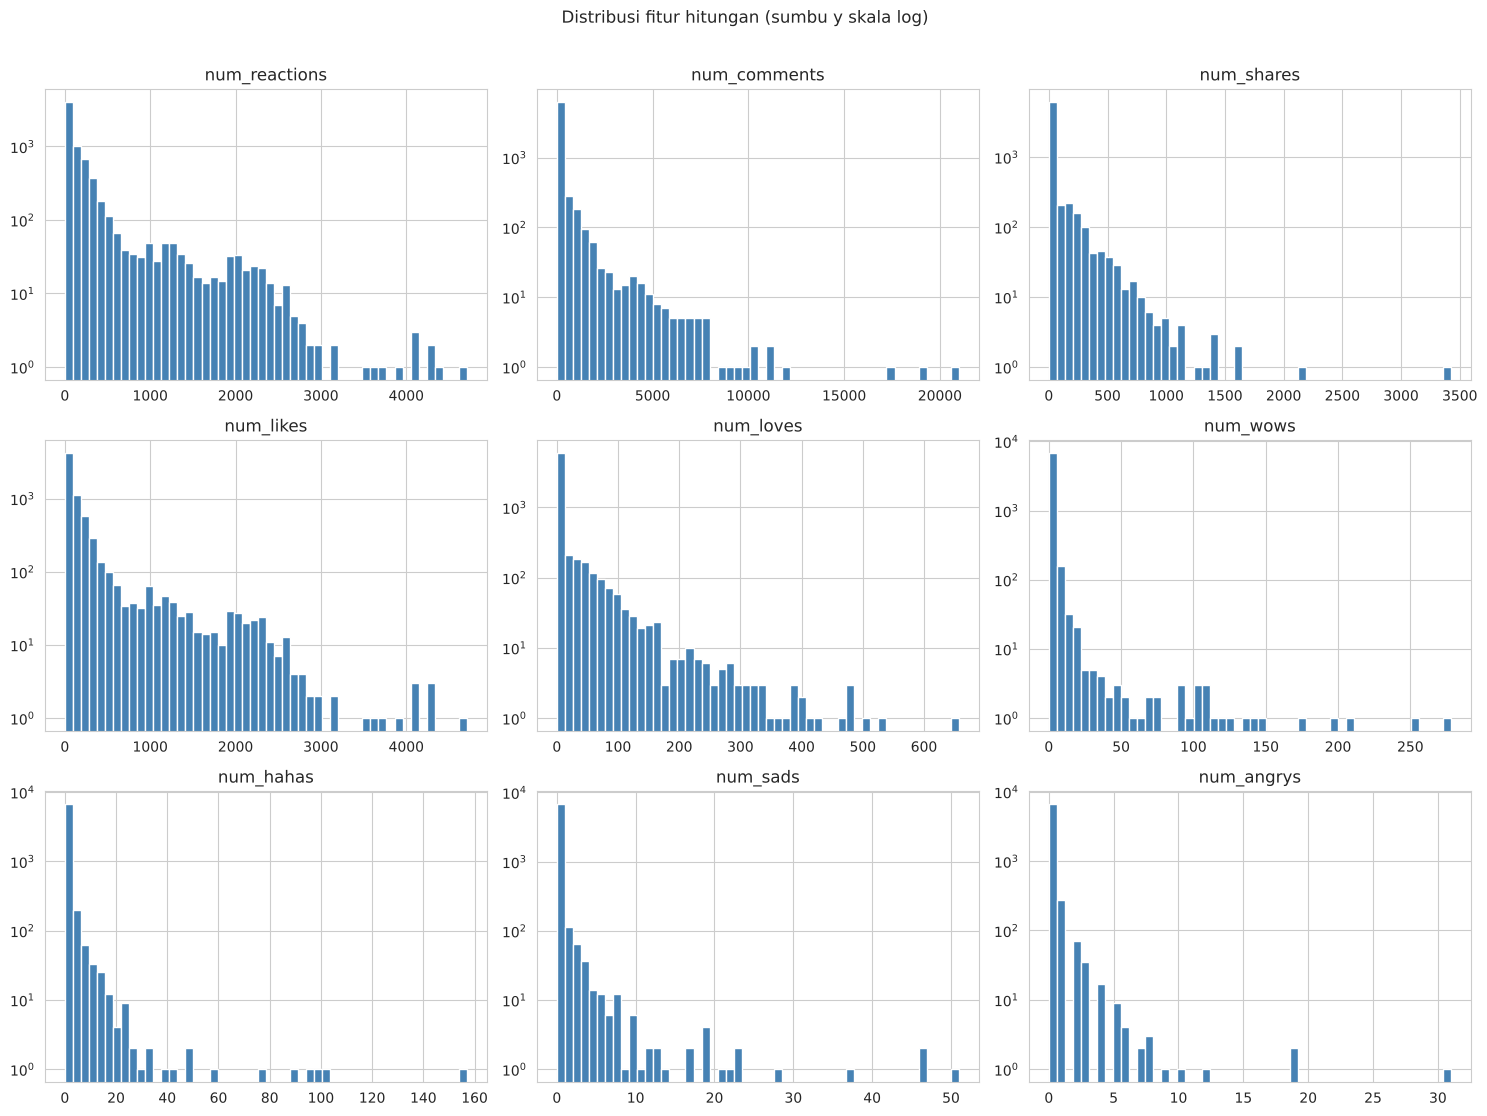

,skewness,proporsi_nol,median,mean,max
num_reactions,3.738,0.017,59.5,230.117,4710
num_comments,9.029,0.301,4.0,224.356,20990
num_shares,7.099,0.555,0.0,40.023,3424
num_likes,3.919,0.018,58.0,215.043,4710
num_loves,6.005,0.600,0.0,12.729,657
num_wows,18.247,0.753,0.0,1.289,278
num_hahas,20.306,0.839,0.0,0.696,157
num_sads,17.579,0.914,0.0,0.244,51
num_angrys,19.507,0.940,0.0,0.113,31


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.

fitur_hitung = ["num_reactions", "num_comments", "num_shares", "num_likes",
                "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), fitur_hitung):
    ax.hist(df[col], bins=50, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_yscale("log")   # skala log di sumbu y agar batang yang kecil tetap terlihat
plt.suptitle("Distribusi fitur hitungan (sumbu y skala log)", y=1.01)
plt.tight_layout()
plt.show()

ringkas = pd.DataFrame({
    "skewness": df[fitur_hitung].skew(),
    "proporsi_nol": (df[fitur_hitung] == 0).mean(),
    "median": df[fitur_hitung].median(),
    "mean": df[fitur_hitung].mean(),
    "max": df[fitur_hitung].max(),
})
display(ringkas.round(3))


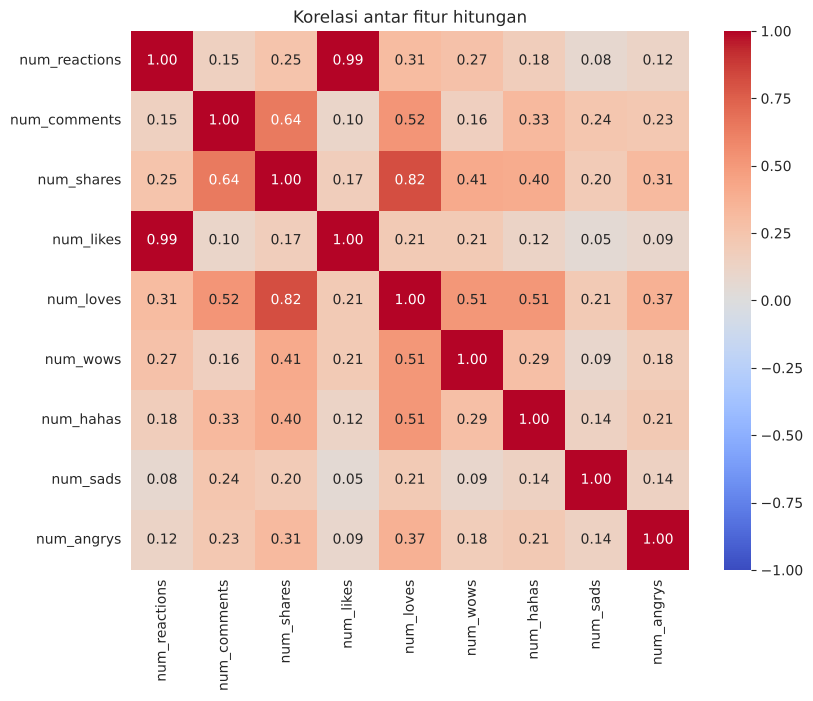

Baris dengan num_reactions != jumlah jenis reaksi: 9
Selisih terbesar: 4


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.

plt.figure(figsize=(9, 7))
sns.heatmap(df[fitur_hitung].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi antar fitur hitungan")
plt.show()

# num_reactions seharusnya = jumlah semua jenis reaksi (like + love + wow + haha + sad + angry)
jumlah_reaksi = df[["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
selisih = (df["num_reactions"] - jumlah_reaksi)
print("Baris dengan num_reactions != jumlah jenis reaksi:", (selisih != 0).sum())
print("Selisih terbesar:", selisih.abs().max())


,jumlah_posting,proporsi_ada_emoji
tahun,,
2012,589,0.000
2013,500,0.000
2014,233,0.000
2015,337,0.000
2016,588,0.680
2017,2253,0.542
2018,2550,0.578


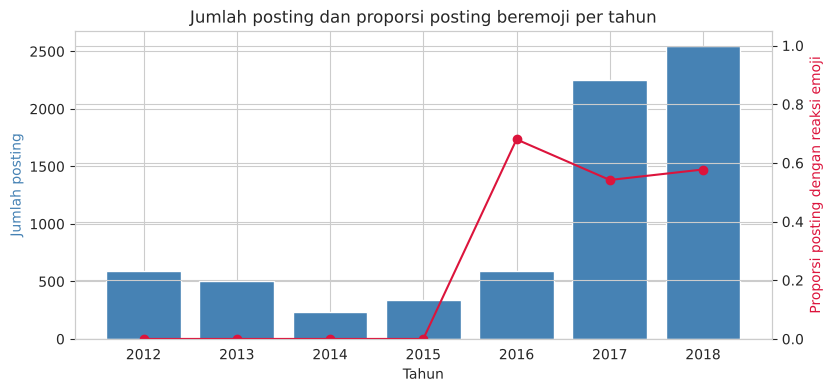

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.

df["status_published"] = pd.to_datetime(df["status_published"], format="%m/%d/%Y %H:%M")
df["tahun"] = df["status_published"].dt.year

df["ada_emoji"] = (df[["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1) > 0)

per_tahun = df.groupby("tahun").agg(jumlah_posting=("status_id", "count"),
                                    proporsi_ada_emoji=("ada_emoji", "mean"))
display(per_tahun.round(3))

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(per_tahun.index, per_tahun["jumlah_posting"], color="steelblue")
ax1.set_xlabel("Tahun")
ax1.set_ylabel("Jumlah posting", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(per_tahun.index, per_tahun["proporsi_ada_emoji"], color="crimson", marker="o")
ax2.set_ylabel("Proporsi posting dengan reaksi emoji", color="crimson")
ax2.set_ylim(0, 1.05)
plt.title("Jumlah posting dan proporsi posting beremoji per tahun")
plt.show()


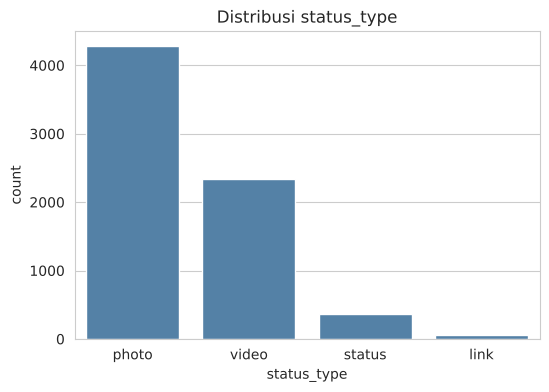

status_type
photo     4288
video     2334
status     365
link        63
Name: count, dtype: int64


,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


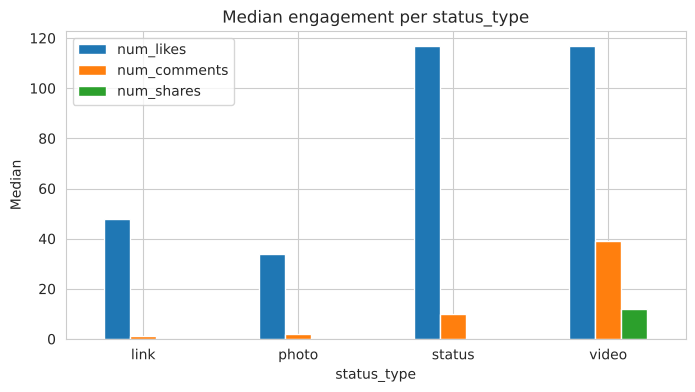

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="status_type", order=df["status_type"].value_counts().index, color="steelblue")
plt.title("Distribusi status_type")
plt.show()
print(df["status_type"].value_counts())

median_tipe = df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]].median()
display(median_tipe)

median_tipe.plot(kind="bar", figsize=(8, 4))
plt.title("Median engagement per status_type")
plt.ylabel("Median")
plt.xticks(rotation=0)
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

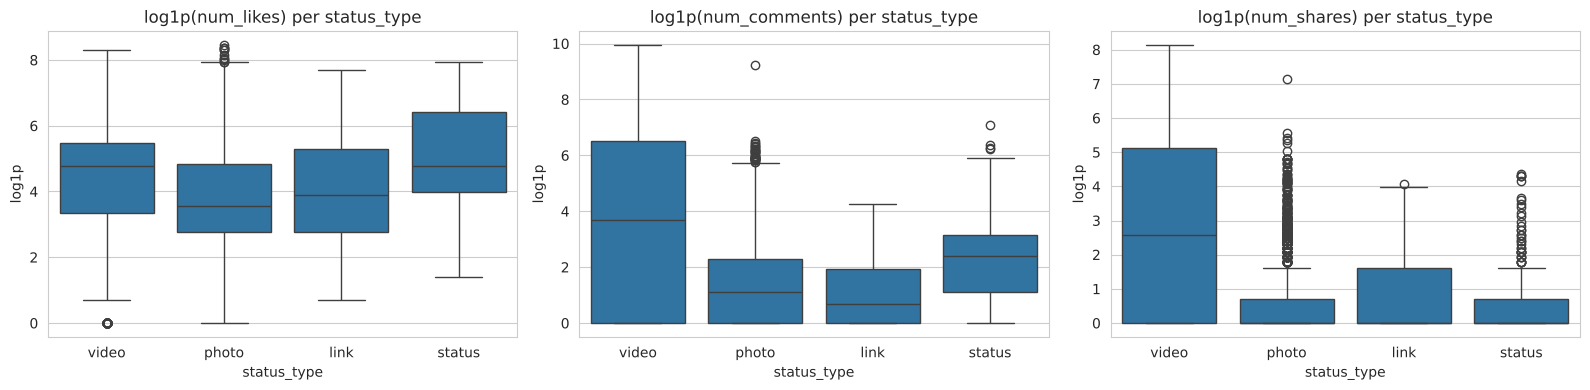

In [7]:
# EDA tambahan 1: engagement per status_type (skala log) dan per tahun
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["num_likes", "num_comments", "num_shares"]):
    sns.boxplot(data=df, x="status_type", y=np.log1p(df[col]), ax=ax)
    ax.set_title(f"log1p({col}) per status_type")
    ax.set_ylabel("log1p")
plt.tight_layout()
plt.show()

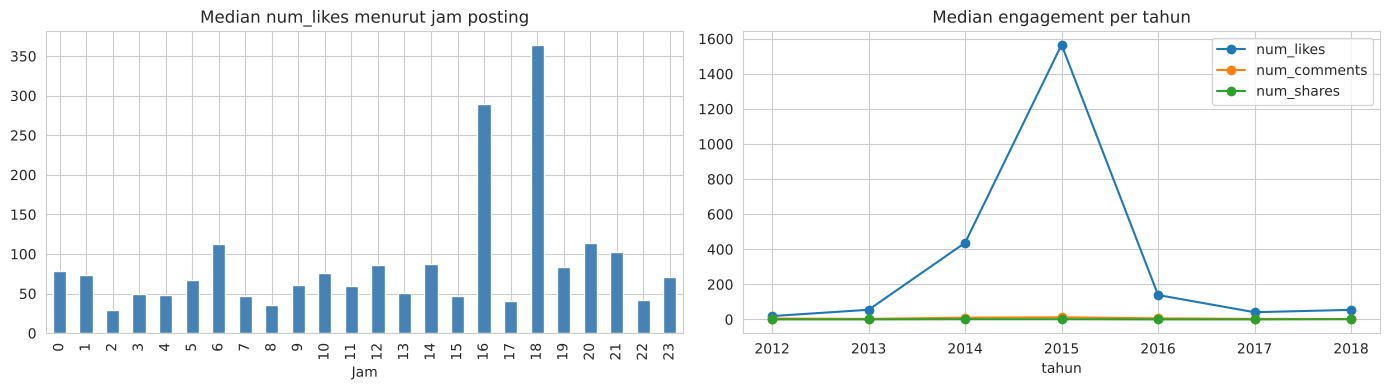

Posting dengan num_comments terbesar:


,status_type,status_published,num_reactions,num_comments,num_shares
498,video,2016-11-30 08:46:00,564,20990,154
480,video,2016-12-09 21:48:00,452,19013,161
6757,video,2017-09-25 10:35:00,708,17404,913
3246,video,2018-01-08 01:10:00,624,12003,856
6762,video,2017-09-21 08:01:00,634,10960,783


In [8]:
# EDA tambahan 2: rasio share terhadap like dan pola jam posting
df["jam"] = df["status_published"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("jam")["num_likes"].median().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Median num_likes menurut jam posting")
axes[0].set_xlabel("Jam")

median_tahun = df.groupby("tahun")[["num_likes", "num_comments", "num_shares"]].median()
median_tahun.plot(marker="o", ax=axes[1])
axes[1].set_title("Median engagement per tahun")
plt.tight_layout()
plt.show()

print("Posting dengan num_comments terbesar:")
display(df.sort_values("num_comments", ascending=False)[["status_type", "status_published", "num_reactions", "num_comments", "num_shares"]].head(5))

# 2. Preprocessing

In [9]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.

# 1. Hapus kolom yang seluruhnya kosong
df = df.drop(columns=kolom_kosong)
print("Kolom setelah drop kolom kosong:", list(df.columns))

# 2. Duplikat: status_id selalu unik, jadi cek duplikat dengan mengabaikan status_id
kolom_cek = [c for c in df.columns if c not in ["status_id", "tahun", "ada_emoji"]]
dup = df[df.duplicated(subset=kolom_cek, keep=False)].sort_values(kolom_cek)
print("Baris yang terlibat duplikat:", len(dup))
display(dup.head(6))

n_sebelum = len(df)
df = df.drop_duplicates(subset=kolom_cek, keep="first").reset_index(drop=True)
print(f"Baris sebelum: {n_sebelum}, sesudah: {len(df)}, dihapus: {n_sebelum - len(df)}")

# 3. Missing value
print("\nTotal missing value:", df.isnull().sum().sum())

# 4. Outlier ekstrem (aturan IQR, hanya untuk melihat seberapa banyak)
out = {}
for col in ["num_comments", "num_shares", "num_likes", "num_loves"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    out[col] = [(df[col] > batas).sum(), round((df[col] > batas).mean() * 100, 1), df[col].max()]
display(pd.DataFrame(out, index=["jumlah_outlier", "persen_outlier", "nilai_max"]).T)


Kolom setelah drop kolom kosong: ['status_id', 'status_type', 'status_published', 'num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys', 'tahun', 'ada_emoji', 'jam']
Baris yang terlibat duplikat: 108


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,tahun,ada_emoji,jam
3762,3763,photo,2017-07-10 08:41:00,0,0,0,0,0,0,0,0,0,2017,False,8
3763,3764,photo,2017-07-10 08:41:00,0,0,0,0,0,0,0,0,0,2017,False,8
3738,3739,photo,2017-07-17 07:11:00,0,0,0,0,0,0,0,0,0,2017,False,7
3739,3740,photo,2017-07-17 07:11:00,0,0,0,0,0,0,0,0,0,2017,False,7
6220,6221,photo,2018-03-16 01:57:00,985,71,42,962,5,16,2,0,0,2018,True,1
6271,6272,photo,2018-03-16 01:57:00,985,71,42,962,5,16,2,0,0,2018,True,1


Baris sebelum: 7050, sesudah: 6996, dihapus: 54

Total missing value: 0


,jumlah_outlier,persen_outlier,nilai_max
num_comments,1365.0,19.5,20990.0
num_shares,1382.0,19.8,3424.0
num_likes,754.0,10.8,4710.0
num_loves,1303.0,18.6,657.0


In [10]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

# Pisahkan kolom untuk interpretasi (status_type, status_published) dan kolom ID
meta = df[["status_type", "status_published"]].copy()
df_num = df.drop(columns=["status_id", "status_type", "status_published", "tahun", "ada_emoji", "jam"], errors="ignore")
print("Kolom numerik yang tersisa:", list(df_num.columns))

# Cek redundansi: num_reactions ~ jumlah semua jenis reaksi
cek = df_num["num_reactions"] - df_num[["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
print("Korelasi num_reactions vs num_likes:", round(df_num["num_reactions"].corr(df_num["num_likes"]), 4))
print("Selisih terbesar num_reactions vs jumlah reaksi:", cek.abs().max())

# Proporsi nol tiap fitur
print("\nProporsi nilai nol:")
print((df_num == 0).mean().round(3))

# Gabungkan reaksi emoji yang sangat sparse (wow, haha, sad, angry) jadi satu fitur
df_num["num_other_reactions"] = df_num[["num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
print("\nProporsi nol num_other_reactions:", round((df_num["num_other_reactions"] == 0).mean(), 3))

fitur = ["num_likes", "num_loves", "num_comments", "num_shares", "num_other_reactions"]
X = df_num[fitur].copy()
print("\nFitur terpilih:", fitur)
print("Bentuk X:", X.shape)
display(X.describe().T)


Kolom numerik yang tersisa: ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
Korelasi num_reactions vs num_likes: 0.9947
Selisih terbesar num_reactions vs jumlah reaksi: 4

Proporsi nilai nol:
num_reactions    0.017
num_comments     0.302
num_shares       0.558
num_likes        0.018
num_loves        0.604
num_wows         0.757
num_hahas        0.840
num_sads         0.915
num_angrys       0.940
dtype: float64

Proporsi nol num_other_reactions: 0.689

Fitur terpilih: ['num_likes', 'num_loves', 'num_comments', 'num_shares', 'num_other_reactions']
Bentuk X: (6996, 5)


,count,mean,std,min,25%,50%,75%,max
num_likes,6996.0,210.036735,439.623067,0.0,17.0,57.0,182.00,4710.0
num_loves,6996.0,12.757004,40.114602,0.0,0.0,0.0,3.00,657.0
num_comments,6996.0,225.648799,892.922206,0.0,0.0,4.0,22.25,20990.0
num_shares,6996.0,40.275872,132.072584,0.0,0.0,0.0,4.00,3424.0
num_other_reactions,6996.0,2.294597,11.073101,0.0,0.0,0.0,1.00,286.0


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_loves`, `num_comments`, `num_shares`, dan `num_other_reactions` (gabungan `num_wows` + `num_hahas` + `num_sads` + `num_angrys`).

Alasan pemilihan:
- **`num_reactions` dibuang** karena redundan. Nilainya hampir sama dengan jumlah semua jenis reaksi (selisih maksimal hanya 4, pada 9 baris) dan korelasinya dengan `num_likes` 0,99. Kalau ikut dipakai, informasi "reaksi" terhitung dua kali dan jaraknya jadi condong ke dimensi itu.
- **`num_wows`, `num_hahas`, `num_sads`, `num_angrys` digabung** menjadi `num_other_reactions`. Masing-masing 75% sampai 94% bernilai nol, jadi kalau dipakai sendiri-sendiri hampir tidak membawa informasi dan hanya menambah dimensi berisi nol. Setelah digabung, proporsi nol turun jadi sekitar 69%.
- **`num_loves` tetap dipakai** sendiri karena proporsi nolnya 60% dan nilainya cukup bervariasi (maksimum 657), jadi masih bisa membedakan posting.
- `num_likes`, `num_comments`, dan `num_shares` dipakai karena merupakan tiga bentuk utama engagement.
- `status_type` dan `status_published` **tidak dipakai** sebagai fitur, hanya disimpan di `meta` untuk interpretasi cluster.
- **Duplikat:** ada 54 baris yang isinya identik (selain `status_id`, termasuk waktu posting yang sama), jadi dihapus. Tersisa 6.996 baris.
- **Outlier tidak dibuang.** Posting dengan ribuan komentar adalah posting viral yang memang asli, bukan kesalahan data, dan justru itu yang ingin kita temukan. Pengaruhnya diredam dengan transformasi log1p.

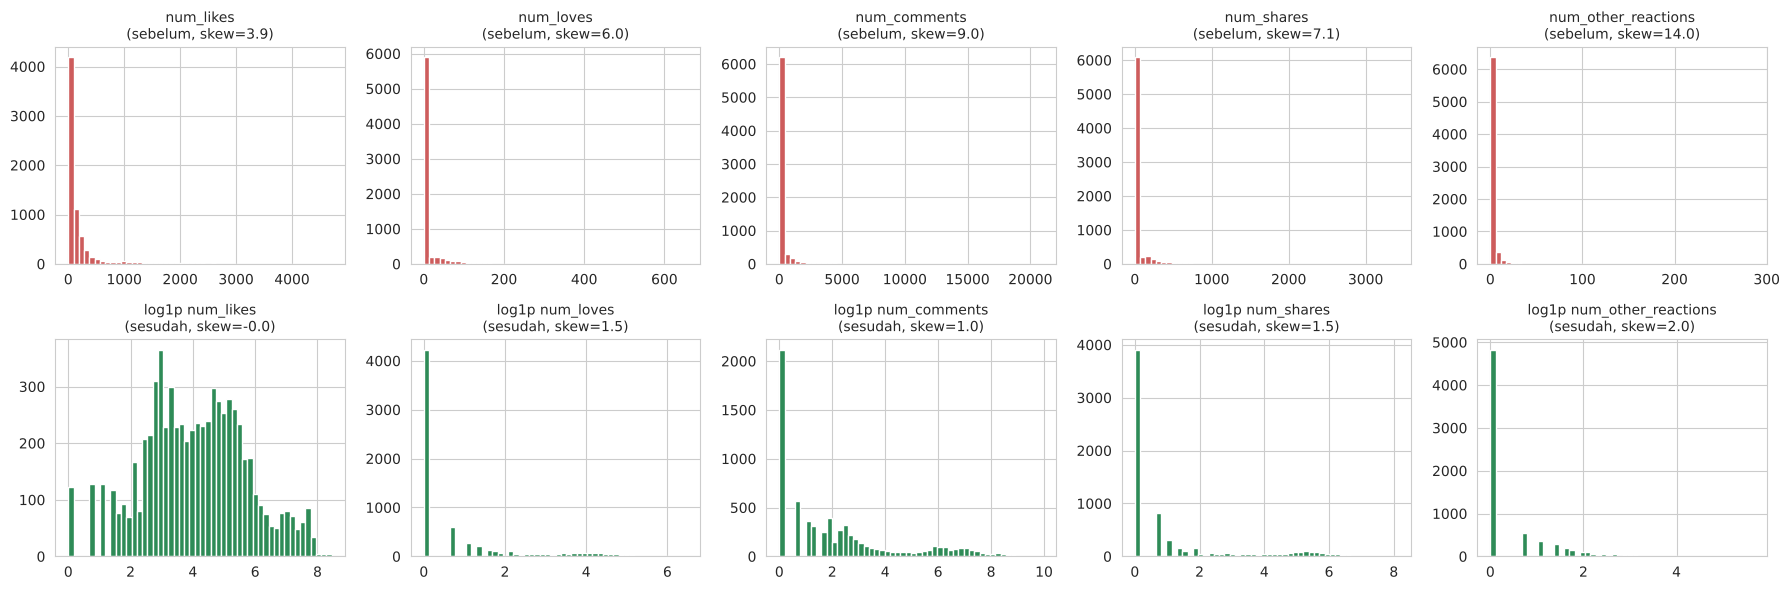

In [11]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.

X_log = np.log1p(X)

fig, axes = plt.subplots(2, len(fitur), figsize=(18, 6))
for i, col in enumerate(fitur):
    axes[0, i].hist(X[col], bins=50, color="indianred", edgecolor="white")
    axes[0, i].set_title(f"{col}\n(sebelum, skew={X[col].skew():.1f})", fontsize=10)
    axes[1, i].hist(X_log[col], bins=50, color="seagreen", edgecolor="white")
    axes[1, i].set_title(f"log1p {col}\n(sesudah, skew={X_log[col].skew():.1f})", fontsize=10)
plt.tight_layout()
plt.show()


In [12]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja

scaler = StandardScaler()
X_log_scaled = scaler.fit_transform(X_log)

# Versi pembanding untuk bagian 3.1
X_raw = X.values
X_raw_scaled = StandardScaler().fit_transform(X)

print("X_raw          :", X_raw.shape)
print("X_raw_scaled   :", X_raw_scaled.shape)
print("X_log_scaled   :", X_log_scaled.shape)
print("\nRata-rata dan std X_log_scaled (harus ~0 dan ~1):")
print(pd.DataFrame(X_log_scaled, columns=fitur).agg(["mean", "std"]).round(3))
print("\nStd tiap fitur pada X_raw (perbedaan skala):")
print(pd.Series(X_raw.std(axis=0), index=fitur).round(2))


X_raw          : (6996, 5)
X_raw_scaled   : (6996, 5)
X_log_scaled   : (6996, 5)

Rata-rata dan std X_log_scaled (harus ~0 dan ~1):
      num_likes  num_loves  num_comments  num_shares  num_other_reactions
mean       -0.0       -0.0          -0.0         0.0                 -0.0
std         1.0        1.0           1.0         1.0                  1.0

Std tiap fitur pada X_raw (perbedaan skala):
num_likes              439.59
num_loves               40.11
num_comments           892.86
num_shares             132.06
num_other_reactions     11.07
dtype: float64


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [13]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.

K_UJI = 3
versi_data = {"X_raw": X_raw, "X_raw_scaled": X_raw_scaled, "X_log_scaled": X_log_scaled}

label_versi = {}
for nama, data in versi_data.items():
    km = KMeans(n_clusters=K_UJI, random_state=RANDOM_STATE, n_init=10)
    label_versi[nama] = km.fit_predict(data)
    print(nama, "selesai | inertia =", round(km.inertia_, 1))


X_raw selesai | inertia = 2365702246.8
X_raw_scaled selesai | inertia = 17209.6
X_log_scaled selesai | inertia = 10144.1


,Data,Ukuran cluster 0,Ukuran cluster 1,Ukuran cluster 2,Silhouette (di X_log_scaled)
0,X_raw,6392,137,467,0.2982
1,X_raw_scaled,292,6331,373,0.2416
2,X_log_scaled,2200,3647,1149,0.4325


Proporsi varians tiap fitur pada X_raw:
num_likes              0.1914
num_loves              0.0016
num_comments           0.7896
num_shares             0.0173
num_other_reactions    0.0001
dtype: float64


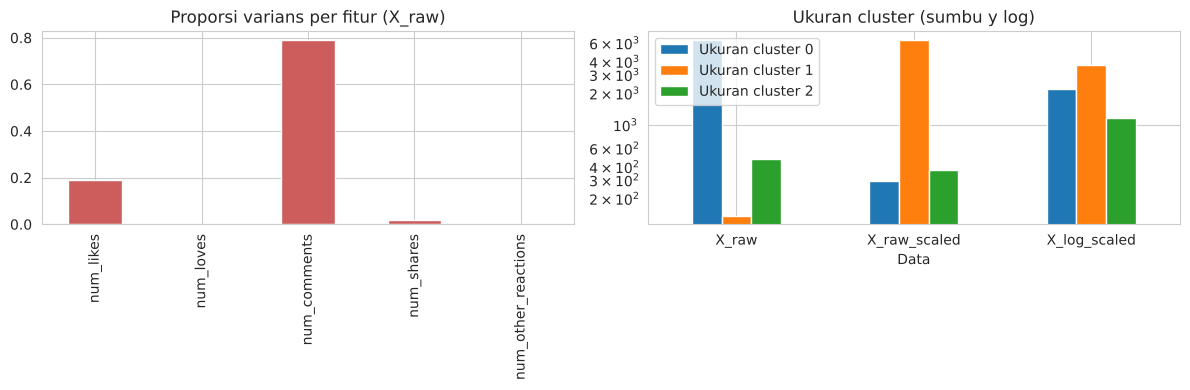

In [14]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.

hasil_31 = []
for nama, lab in label_versi.items():
    ukuran = pd.Series(lab).value_counts().sort_index()
    hasil_31.append({
        "Data": nama,
        "Ukuran cluster 0": ukuran.get(0, 0),
        "Ukuran cluster 1": ukuran.get(1, 0),
        "Ukuran cluster 2": ukuran.get(2, 0),
        # semua dihitung pada ruang X_log_scaled agar adil
        "Silhouette (di X_log_scaled)": round(silhouette_score(X_log_scaled, lab), 4),
    })
tabel_31 = pd.DataFrame(hasil_31)
display(tabel_31)

# Fitur yang mendominasi varians pada data tanpa scaling
var_raw = pd.Series(X_raw.var(axis=0), index=fitur)
print("Proporsi varians tiap fitur pada X_raw:")
print((var_raw / var_raw.sum()).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(var_raw / var_raw.sum()).plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("Proporsi varians per fitur (X_raw)")
tabel_31.set_index("Data")[["Ukuran cluster 0", "Ukuran cluster 1", "Ukuran cluster 2"]].plot(kind="bar", ax=axes[1], logy=True)
axes[1].set_title("Ukuran cluster (sumbu y log)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [15]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.

K_RANGE = range(2, 11)
inertia = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_log_scaled)
    inertia.append(km.inertia_)

display(pd.DataFrame({"k": list(K_RANGE), "inertia": np.round(inertia, 1)}))


,k,inertia
0,2,15075.9
1,3,10144.1
2,4,8448.7
3,5,7360.9
4,6,6348.5
5,7,5737.2
6,8,5306.3
7,9,4878.5
8,10,4584.5


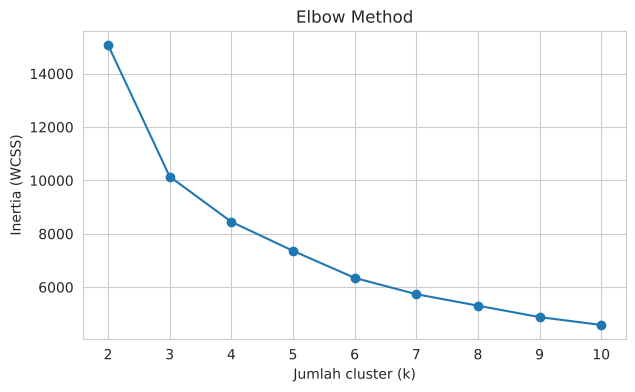

Elbow menurut KneeLocator: k = 4


In [16]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), inertia, marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.xticks(list(K_RANGE))
plt.show()

if ada_kneed:
    kl = KneeLocator(list(K_RANGE), inertia, curve="convex", direction="decreasing")
    print("Elbow menurut KneeLocator: k =", kl.elbow)
else:
    print("kneed tidak terpasang, elbow diamati secara visual.")


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [17]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

sil_scores = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lab = km.fit_predict(X_log_scaled)
    sil_scores.append(silhouette_score(X_log_scaled, lab))

display(pd.DataFrame({"k": list(K_RANGE), "silhouette": np.round(sil_scores, 4)}))


,k,silhouette
0,2,0.5871
1,3,0.4325
2,4,0.4122
3,5,0.3989
4,6,0.3049
5,7,0.3104
6,8,0.2989
7,9,0.3022
8,10,0.2984


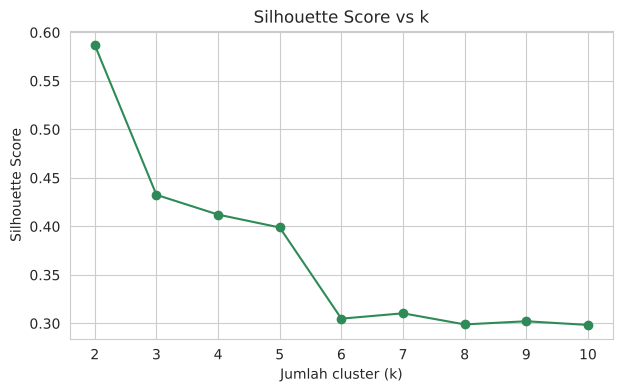

k dengan silhouette tertinggi: 2 -> 0.5871


In [18]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.

plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), sil_scores, marker="o", color="seagreen")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs k")
plt.xticks(list(K_RANGE))
plt.show()

k_sil = list(K_RANGE)[int(np.argmax(sil_scores))]
print("k dengan silhouette tertinggi:", k_sil, "->", round(max(sil_scores), 4))


**Pilihan k untuk K-Means: k = 3**

- **Elbow:** penurunan inertia terbesar ada dari k=2 ke k=3 (15.076 menjadi 10.144), lalu melandai (k=4: 8.449, k=5: 7.361). Siku terlihat di sekitar k=3 sampai 4, dan `KneeLocator` menunjuk k=4.
- **Silhouette:** tertinggi pada k=2 (0,587), lalu k=3 (0,433) dan k=4 (0,412). Setelah k=5 nilainya turun ke sekitar 0,30.
- **Keputusan:** kedua metode tidak sepenuhnya sepakat (Silhouette ke k=2, Elbow ke k=4), jadi saya ambil k=3 sebagai kompromi. Dengan k=2 data hanya terbagi jadi "sepi" dan "ramai", padahal kelompok posting viral (komentar dan share sangat tinggi) menarik untuk dipisahkan. Selisih Silhouette k=3 dan k=4 kecil, tetapi k=3 lebih sederhana dan lebih mudah ditafsirkan. Dendrogram juga mendukung: lompatan tinggi penggabungan masih besar dari 4 ke 3 cluster (44,6 ke 61,9) dan dari 3 ke 2 (61,9 ke 105,2).

## 3.4 Model K-Means Final

In [19]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

BEST_K = 3

kmeans_final = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
label_kmeans = kmeans_final.fit_predict(X_log_scaled)
print("Ukuran cluster K-Means:")
print(pd.Series(label_kmeans).value_counts().sort_index())


Ukuran cluster K-Means:
0    2200
1    3647
2    1149
Name: count, dtype: int64


In [20]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.

def buat_profil(data_asli, label):
    tmp = data_asli.copy()
    tmp["cluster"] = label
    median = tmp.groupby("cluster")[fitur].median().add_prefix("median_")
    rata = tmp.groupby("cluster")[fitur].mean().add_prefix("mean_")
    ukuran = tmp.groupby("cluster").size().rename("jumlah")
    return pd.concat([ukuran, median, rata], axis=1).round(2)

profil_kmeans = buat_profil(X, label_kmeans)
display(profil_kmeans)


,jumlah,median_num_likes,median_num_loves,median_num_comments,median_num_shares,median_num_other_reactions,mean_num_likes,mean_num_loves,mean_num_comments,mean_num_shares,mean_num_other_reactions
cluster,,,,,,,,,,,
0,2200,204.5,1.0,11.0,1.0,0.0,458.46,2.62,28.02,5.03,1.57
1,3647,18.0,0.0,0.0,0.0,0.0,23.00,0.14,2.22,0.55,0.06
2,1149,177.0,51.0,703.0,174.0,4.0,328.04,72.19,1313.25,233.87,10.75


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [21]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.

Z = linkage(X_log_scaled, method="ward")
print("Bentuk linkage matrix:", Z.shape)


Bentuk linkage matrix: (6995, 4)


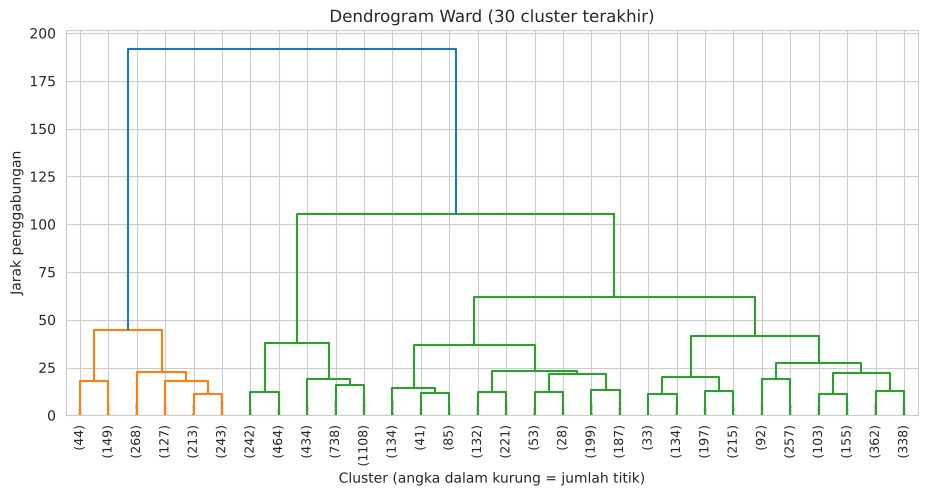

Tinggi penggabungan pada 10 langkah terakhir:
  menggabungkan 2 cluster menjadi 1: tinggi = 191.90
  menggabungkan 3 cluster menjadi 2: tinggi = 105.23
  menggabungkan 4 cluster menjadi 3: tinggi = 61.93
  menggabungkan 5 cluster menjadi 4: tinggi = 44.59
  menggabungkan 6 cluster menjadi 5: tinggi = 41.27
  menggabungkan 7 cluster menjadi 6: tinggi = 37.82
  menggabungkan 8 cluster menjadi 7: tinggi = 36.70
  menggabungkan 9 cluster menjadi 8: tinggi = 27.19
  menggabungkan 10 cluster menjadi 9: tinggi = 22.92
  menggabungkan 11 cluster menjadi 10: tinggi = 22.67


In [22]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.

plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title("Dendrogram Ward (30 cluster terakhir)")
plt.xlabel("Cluster (angka dalam kurung = jumlah titik)")
plt.ylabel("Jarak penggabungan")
plt.show()

# Jarak penggabungan pada 10 langkah terakhir untuk membantu memilih titik potong
print("Tinggi penggabungan pada 10 langkah terakhir:")
tinggi = Z[-10:, 2][::-1]
for j, h in enumerate(tinggi):
    print(f"  menggabungkan {j + 2} cluster menjadi {j + 1}: tinggi = {h:.2f}")


## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [23]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.

daftar_linkage = ["ward", "complete", "average", "single"]
label_linkage = {}
for lk in daftar_linkage:
    agg = AgglomerativeClustering(n_clusters=BEST_K, linkage=lk)
    label_linkage[lk] = agg.fit_predict(X_log_scaled)
    print(lk, "selesai")


ward selesai


complete selesai


average selesai
single selesai


,Linkage,Silhouette,Ukuran cluster (besar ke kecil)
0,ward,0.3757,"[2986, 2966, 1044]"
1,complete,0.4784,"[5403, 1246, 347]"
2,average,0.5726,"[5892, 1075, 29]"
3,single,0.3526,"[6994, 1, 1]"


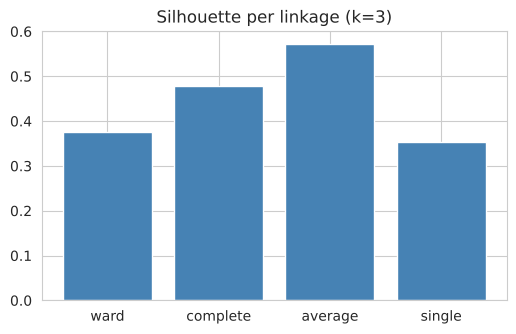

In [24]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).

baris = []
for lk, lab in label_linkage.items():
    ukuran = sorted(pd.Series(lab).value_counts().tolist(), reverse=True)
    baris.append({
        "Linkage": lk,
        "Silhouette": round(silhouette_score(X_log_scaled, lab), 4),
        "Ukuran cluster (besar ke kecil)": ukuran,
    })
tabel_linkage = pd.DataFrame(baris)
display(tabel_linkage)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(tabel_linkage["Linkage"], tabel_linkage["Silhouette"], color="steelblue")
ax.set_title(f"Silhouette per linkage (k={BEST_K})")
plt.show()


**Pilihan linkage untuk Hierarchical Clustering: ward**

Dengan k=3, Silhouette tertinggi sebenarnya dimiliki average (0,573) dan complete (0,478), sementara ward 0,376 dan single 0,353. Tetapi average menghasilkan cluster berukuran [5892, 1075, 29] dan complete [5403, 1246, 347], artinya sebagian besar data tertumpuk pada satu cluster dan sisanya kecil. Single linkage lebih parah, [6994, 1, 1], karena hanya mengambil dua titik ekstrem. Silhouette yang tinggi di sini tidak berarti cluster-nya lebih bermakna, melainkan karena cluster kecil berisi outlier terpisah jauh dari yang lain.

Ward menghasilkan cluster yang seimbang ([2986, 2966, 1044]) dan mudah ditafsirkan. Ward juga meminimalkan kenaikan varians dalam cluster, sama seperti tujuan K-Means, sehingga perbandingan keduanya lebih adil. Karena itu ward dipilih.

## 4.3 Model Hierarchical Clustering Final

In [25]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

LINKAGE_TERPILIH = "ward"

hc_final = AgglomerativeClustering(n_clusters=BEST_K, linkage=LINKAGE_TERPILIH)
label_hc = hc_final.fit_predict(X_log_scaled)
print("Ukuran cluster Hierarchical:")
print(pd.Series(label_hc).value_counts().sort_index())


Ukuran cluster Hierarchical:
0    2966
1    1044
2    2986
Name: count, dtype: int64


In [26]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.

profil_hc = buat_profil(X, label_hc)
display(profil_hc)


,jumlah,median_num_likes,median_num_loves,median_num_comments,median_num_shares,median_num_other_reactions,mean_num_likes,mean_num_loves,mean_num_comments,mean_num_shares,mean_num_other_reactions
cluster,,,,,,,,,,,
0,2966,147.0,1.0,9.0,1.0,0.0,380.43,2.70,27.94,5.16,1.76
1,1044,166.5,55.0,809.5,192.5,4.0,277.42,77.58,1427.88,254.45,10.38
2,2986,14.0,0.0,0.0,0.0,0.0,17.22,0.09,1.69,0.27,0.00


# 5. Evaluasi Model

In [27]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.

def hitung_metrik(data, label):
    return {
        "Silhouette (↑)": silhouette_score(data, label),
        "Davies-Bouldin (↓)": davies_bouldin_score(data, label),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(data, label),
    }

tabel_eval = pd.DataFrame({
    "K-Means": hitung_metrik(X_log_scaled, label_kmeans),
    f"Hierarchical ({LINKAGE_TERPILIH})": hitung_metrik(X_log_scaled, label_hc),
}).T.round(4)
display(tabel_eval)


,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
K-Means,0.4325,0.9541,8560.4928
Hierarchical (ward),0.3757,0.9476,7591.1220


Varians dijelaskan PC1: 73.1%
Varians dijelaskan PC2: 13.3%
Total: 86.5%


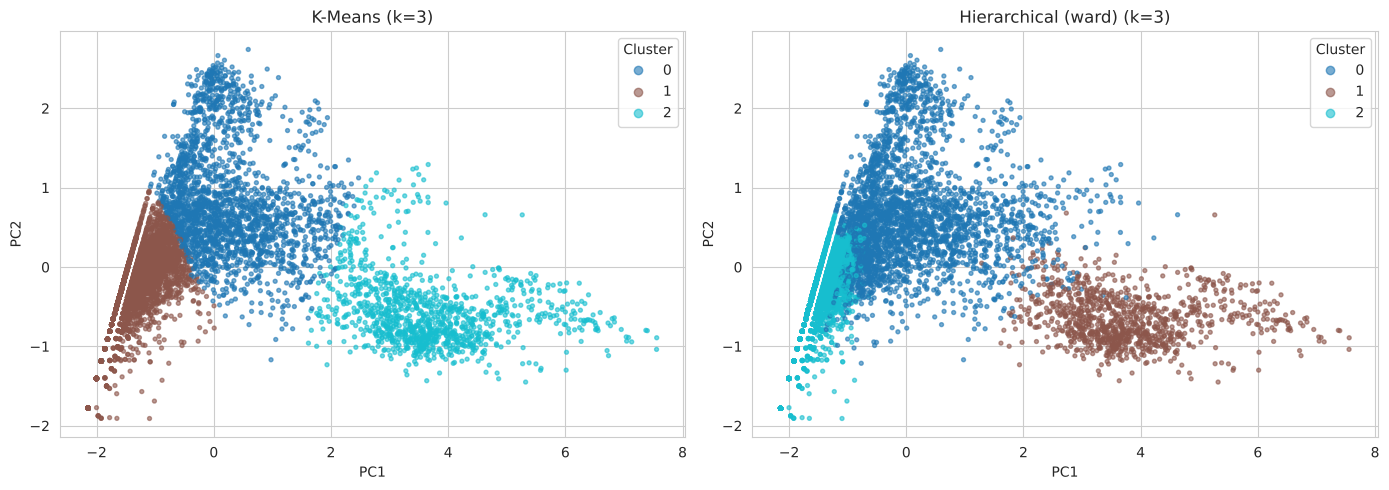

In [28]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
print("Varians dijelaskan PC1: {:.1f}%".format(pca.explained_variance_ratio_[0] * 100))
print("Varians dijelaskan PC2: {:.1f}%".format(pca.explained_variance_ratio_[1] * 100))
print("Total: {:.1f}%".format(pca.explained_variance_ratio_.sum() * 100))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, judul in zip(axes, [label_kmeans, label_hc],
                          ["K-Means", f"Hierarchical ({LINKAGE_TERPILIH})"]):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap="tab10", s=8, alpha=0.6)
    ax.set_title(f"{judul} (k={BEST_K})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(*sc.legend_elements(), title="Cluster", loc="best")
plt.tight_layout()
plt.show()


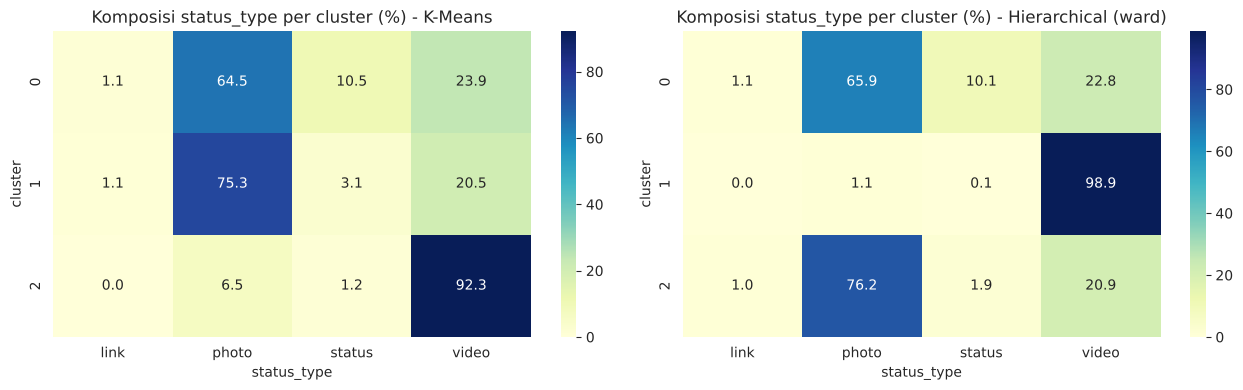

In [29]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, lab, judul in zip(axes, [label_kmeans, label_hc],
                          ["K-Means", f"Hierarchical ({LINKAGE_TERPILIH})"]):
    ct = pd.crosstab(lab, meta["status_type"], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax)
    ax.set_title(f"Komposisi status_type per cluster (%) - {judul}")
    ax.set_xlabel("status_type")
    ax.set_ylabel("cluster")
plt.tight_layout()
plt.show()


In [30]:
# Tambahan: seberapa mirip hasil K-Means dan Hierarchical? (cluster dibandingkan satu sama lain)
from sklearn.metrics import adjusted_rand_score

print("Adjusted Rand Index K-Means vs Hierarchical:", round(adjusted_rand_score(label_kmeans, label_hc), 4))
print()
print("Crosstab (baris = K-Means, kolom = Hierarchical):")
display(pd.crosstab(label_kmeans, label_hc, rownames=["K-Means"], colnames=["Hierarchical"]))

# Sebaran tahun posting pada tiap cluster K-Means (untuk melihat pengaruh reaksi emoji sebelum 2016)
tahun = meta["status_published"].dt.year
print("\nProporsi tahun posting per cluster K-Means:")
display(pd.crosstab(label_kmeans, tahun, normalize="index").round(2))

Adjusted Rand Index K-Means vs Hierarchical: 0.669

Crosstab (baris = K-Means, kolom = Hierarchical):


Hierarchical,0,1,2
K-Means,,,
0,2197,3,0
1,661,0,2986
2,108,1041,0



Proporsi tahun posting per cluster K-Means:


status_published,2012,2013,2014,2015,2016,2017,2018
row_0,,,,,,,
0,0.00,0.07,0.10,0.15,0.20,0.25,0.24
1,0.16,0.10,0.01,0.00,0.04,0.34,0.36
2,0.00,0.00,0.00,0.00,0.02,0.39,0.58


# 6. Analisis

## Analisis

**1. Pengaruh transformasi log dan scaling pada K-Means (bagian 3.1)**

Dengan k=3 yang sama, hasilnya berbeda jauh pada tiga versi data:

| Data | Ukuran cluster | Silhouette (di X_log_scaled) |
|---|---|---|
| X_raw | 6392 / 137 / 467 | 0,298 |
| X_raw_scaled | 292 / 6331 / 373 | 0,242 |
| X_log_scaled | 2200 / 3647 / 1149 | 0,433 |

Pada `X_raw`, 79% varians berasal dari `num_comments` dan 19% dari `num_likes`, sedangkan `num_other_reactions` hanya 0,01%. Jarak Euclidean praktis hanya ditentukan oleh komentar dan like, sehingga fitur lain tidak berpengaruh. Cluster yang terbentuk sangat tidak seimbang (satu cluster berisi 6.392 posting).

Scaling saja (`X_raw_scaled`) menyamakan skala, tetapi data masih sangat miring dan punya outlier ekstrem. Hasilnya satu cluster raksasa 6.331 posting (sekitar 90% data) dan dua cluster kecil berisi posting viral. Silhouette-nya malah paling rendah. Artinya scaling saja belum cukup kalau distribusinya masih miring.

Dengan log1p lalu scaling, ekor panjang dipadatkan dan semua fitur punya skala sebanding, sehingga tiga cluster berukuran masuk akal dan Silhouette tertinggi. Catatan: Silhouette dihitung di ruang `X_log_scaled`, jadi sedikit menguntungkan versi log. Meski begitu, perbedaan ukuran cluster sudah cukup jelas menunjukkan bahwa kedua langkah ini penting. Algoritma berbasis jarak sangat sensitif pada skala dan outlier karena centroid adalah rata-rata, dan rata-rata mudah tertarik oleh nilai ekstrem.

**2. Fitur redundan dan sparse**

`num_reactions` dibuang karena hampir sama dengan jumlah reaksi lain. Reaksi emoji yang sangat sparse (wow, haha, sad, angry) digabung menjadi `num_other_reactions`. Perlu diingat bahwa reaksi emoji baru ada sejak 2016, jadi semua posting 2012 sampai 2015 bernilai nol di kolom ini (proporsi posting beremoji 0% pada 2012 sampai 2015 dan 54% sampai 68% pada 2016 sampai 2018). Akibatnya ada sedikit efek era: cluster "sepi" berisi lebih banyak posting tahun 2012 (16%) dibanding cluster lain.

**3. Jumlah cluster optimal**

Elbow menunjuk k sekitar 3 sampai 4 (KneeLocator: 4), sedangkan Silhouette tertinggi di k=2 (0,587). Keduanya tidak sama. Saya memilih k=3 dengan alasan yang sudah ditulis di bagian 3.3: k=2 terlalu kasar, sementara k=3 sudah memisahkan posting viral dan hanya sedikit lebih rendah Silhouette-nya dari k=2.

**4. Perbandingan linkage**

Pada k=3, Silhouette: average 0,573 > complete 0,478 > ward 0,376 > single 0,353. Namun ukuran clusternya: average [5892, 1075, 29], complete [5403, 1246, 347], ward [2986, 2966, 1044], dan single [6994, 1, 1]. Single linkage menghubungkan titik berdasarkan jarak terdekat antar anggota, sehingga terjadi efek *chaining*. Titik-titik padat menyambung jadi satu cluster besar, dan cluster lain hanya berisi 1 titik outlier. Average dan complete juga cenderung menyisihkan outlier. Ward paling seimbang, jadi saya pilih ward meskipun Silhouette-nya lebih rendah. Menurut saya Silhouette tinggi pada linkage lain hanya karena cluster kecilnya sangat terpisah, bukan karena pengelompokannya lebih berguna.

**5. K-Means vs Hierarchical (ward), k=3**

| Metrik | K-Means | Hierarchical (ward) |
|---|---|---|
| Silhouette (↑) | 0,4325 | 0,3757 |
| Davies-Bouldin (↓) | 0,9541 | 0,9476 |
| Calinski-Harabasz (↑) | 8560,5 | 7591,1 |

K-Means unggul pada Silhouette dan Calinski-Harabasz, sedangkan Davies-Bouldin hampir sama (ward sedikit lebih baik). Pada plot PCA (PC1 73,1% + PC2 13,3% = 86,5% varians), bentuk ketiga cluster sangat mirip: kelompok viral di kanan, kelompok sepi di kiri bawah, kelompok menengah di tengah. Bedanya ada pada batas cluster sepi dan menengah. K-Means memasukkan 661 posting yang oleh ward dianggap "menengah" ke cluster sepi. Nilai Adjusted Rand Index kedua hasil adalah 0,67, jadi cukup mirip tetapi tidak identik. Menurut saya perbedaannya kecil karena keduanya sama-sama meminimalkan varians dalam cluster, dan strukturnya memang berbentuk satu gradien (dari sepi ke ramai) tanpa batas yang tegas, sehingga batas antar cluster bisa bergeser sedikit tergantung algoritma.

**6. Karakteristik cluster dan julukannya (K-Means)**

- **Cluster 1, "Posting Sepi"** (3.647 posting): median like 18, komentar 0, share 0, love 0. Kebanyakan foto (75%). Engagement sangat rendah.
- **Cluster 0, "Disukai Tapi Jarang Dibahas"** (2.200 posting): median like 204,5 tetapi komentar hanya 11 dan share 1. Mean like-nya paling tinggi (458). Isinya campuran foto (65%), video (24%), dan status (10,5%). Audiens menyukai posting ini tetapi tidak banyak berinteraksi lebih jauh.
- **Cluster 2, "Viral dan Ramai Diskusi"** (1.149 posting): median komentar 703, share 174, love 51, dan emoji lain 4. Didominasi video (92%) dan hampir seluruhnya dari 2017 sampai 2018, mungkin terkait fitur live video penjual.

Pada Hierarchical (ward) polanya sama: cluster 2 = "Sepi" (2.986), cluster 0 = "Disukai tapi jarang dibahas" (2.966), cluster 1 = "Viral" (1.044, 98,9% video). Status_type hanya dipakai untuk interpretasi, tetapi hasilnya konsisten: video cenderung masuk cluster viral dan foto cenderung masuk cluster sepi atau menengah. Ini juga sejalan dengan median engagement per tipe pada EDA, di mana video punya median komentar dan share paling tinggi.

**7. Kelebihan dan kekurangan metode**

| | K-Means | Hierarchical |
|---|---|---|
| Menentukan k | Harus ditentukan di awal (dibantu Elbow dan Silhouette, yang bisa tidak sepakat) | Tidak perlu di awal, bisa dipotong dari dendrogram |
| Bentuk cluster | Cenderung bulat dan berukuran mirip, sensitif outlier | Tergantung linkage: single mudah chaining, ward cenderung bulat dan seimbang |
| Waktu dan memori | Ringan dan cepat, mudah untuk data besar | Butuh matriks jarak, memori dan waktu sekitar O(n²) atau lebih, berat untuk data besar |
| Hasil | Bergantung inisialisasi (diatasi dengan `n_init` dan `random_state`) | Deterministik, dan dendrogram memperlihatkan struktur bertingkat |
| Kekurangan lain | Perlu scaling dan penanganan outlier | Penggabungan tidak bisa dibatalkan, dendrogram sulit dibaca untuk ribuan data |

Pada 6.996 data ini keduanya masih ringan dijalankan, tetapi K-Means jelas lebih cepat dan lebih mudah diskalakan.

# 7. Kesimpulan dan Saran

## Kesimpulan

- Posting Facebook penjual dapat dikelompokkan menjadi tiga pola engagement: **Posting Sepi**, **Disukai Tapi Jarang Dibahas**, dan **Viral dan Ramai Diskusi**. Cluster viral didominasi video.
- Transformasi **log1p dan scaling terbukti penting**. Tanpa keduanya, `num_comments` mendominasi 79% varians dan cluster menjadi tidak seimbang. Scaling saja tidak cukup untuk data yang miring dan penuh outlier.
- Fitur dipilih dengan membuang `num_reactions` (redundan) dan menggabungkan emoji yang sparse menjadi `num_other_reactions`.
- Jumlah cluster: Elbow menunjuk k sekitar 3 sampai 4, Silhouette tertinggi di k=2. Dipilih **k=3** sebagai kompromi yang masih bisa ditafsirkan.
- Pada Hierarchical Clustering, **ward** dipilih karena cluster-nya seimbang. Single linkage menghasilkan cluster [6994, 1, 1] (chaining), sedangkan average dan complete menyisihkan outlier sehingga Silhouette-nya tinggi tetapi tidak berguna.
- **K-Means sedikit lebih baik** secara metrik internal (Silhouette 0,433 vs 0,376, Calinski-Harabasz 8560 vs 7591; Davies-Bouldin hampir sama), dan hasil keduanya mirip (ARI 0,67). Perbedaan terutama pada batas antara cluster sepi dan menengah.

## Saran

- Clustering dipisah untuk periode **sebelum dan sesudah 2016**, karena reaksi emoji baru ada sejak 2016 sehingga `num_other_reactions` pada data lama selalu nol.
- Menambahkan fitur waktu (jam atau hari posting) dan membandingkannya dengan `status_type` sebagai fitur setelah di-encode.
- Mencoba algoritma lain seperti **DBSCAN** (untuk outlier) atau **Gaussian Mixture Model** (cluster tidak harus bulat).
- Mencoba reduksi dimensi (PCA) sebelum clustering, serta variasi `n_init` dan `init` pada K-Means.
- Mencoba k=4 untuk melihat apakah cluster "Disukai tapi jarang dibahas" bisa dipecah lagi, dan memperhatikan bahwa data berasal dari 10 penjual sehingga perbedaan antar penjual bisa memengaruhi cluster.

*Catatan: hasil bergantung pada `random_state=42`. Nomor cluster bisa berbeda jika dijalankan ulang di lingkungan lain, tetapi ukuran dan profilnya seharusnya serupa.*